11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
RBM Epoch 1 Error: 0.132045584043677
RBM Epoch 2 Error: 0.09646976424512294
RBM Epoch 3 Error: 0.09098462488760754
RBM Epoch 4 Error: 0.08800967393939244
RBM Epoch 5 Error: 0.08540486607208302
DBM Epoch 1 Error: 0.13469055185379694
DBM Epoch 2 Error: 0.08647906747045202
DBM Epoch 3 Error: 0.08576617987967289
DBM Epoch 4 Error: 0.08571305640181379
DBM Epoch 5 Error: 0.08568858668805637

RBM Test Error: 0.08152318572513295
DBM Test Error: 0.08168019845552901
RBM Training Time: 5.53 seconds
DBM Training Time: 7.6 seconds


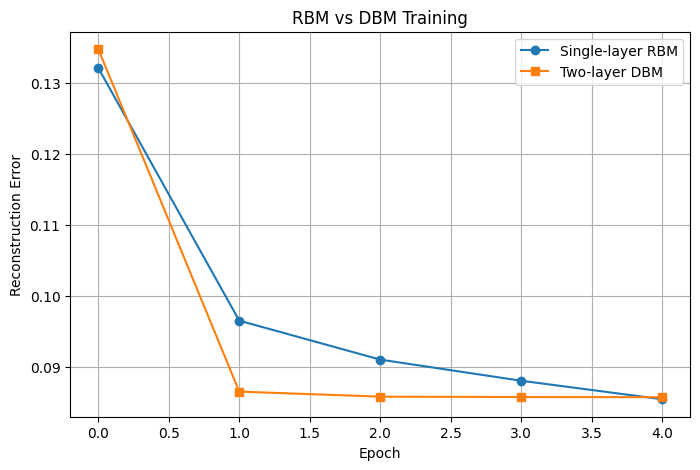

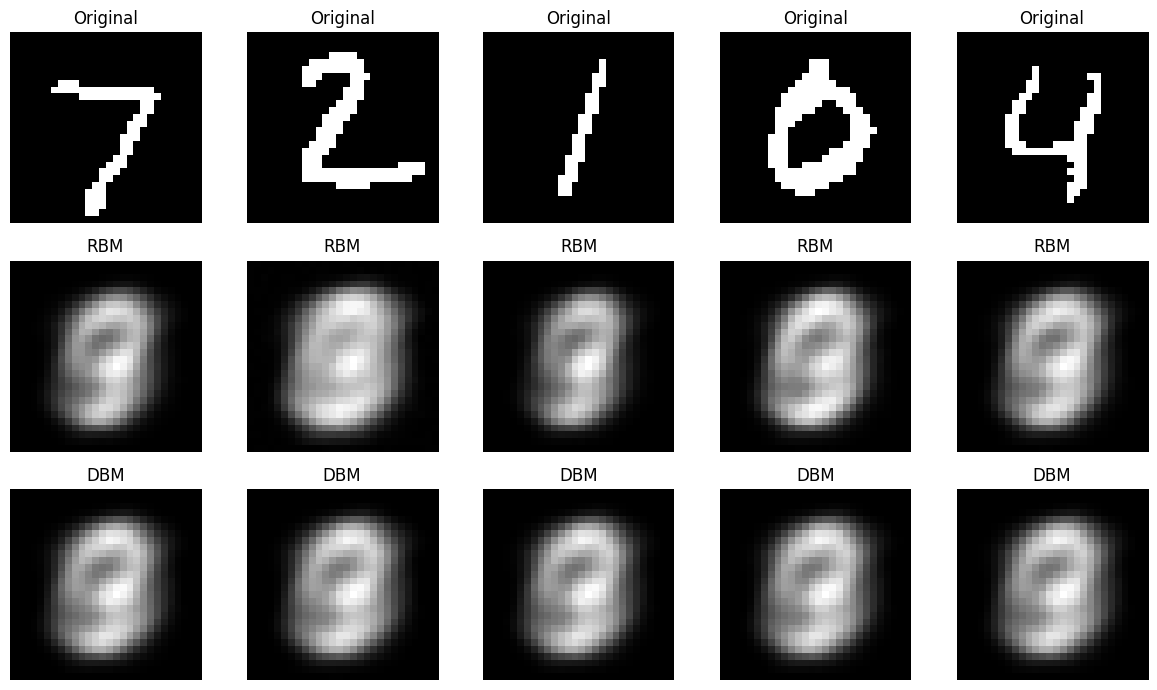

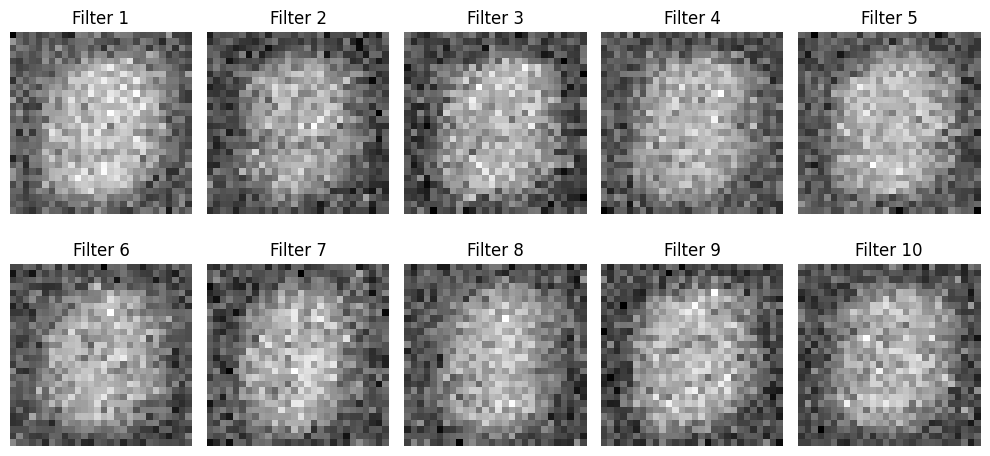

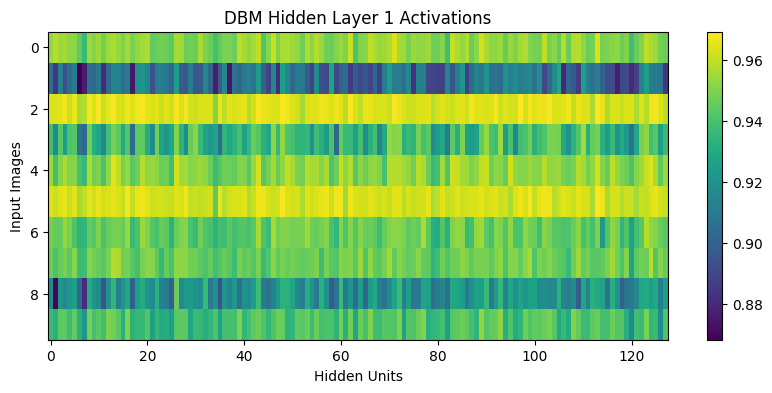

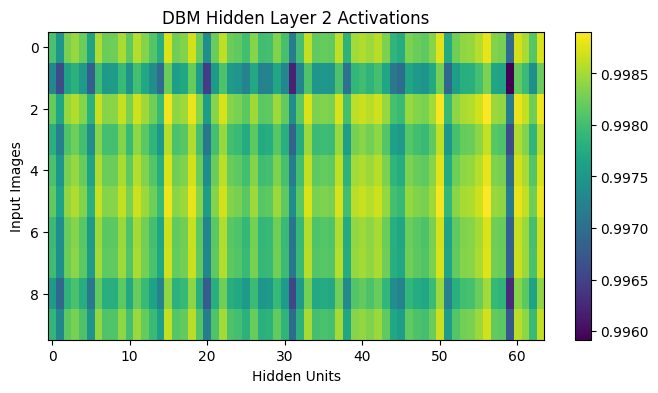

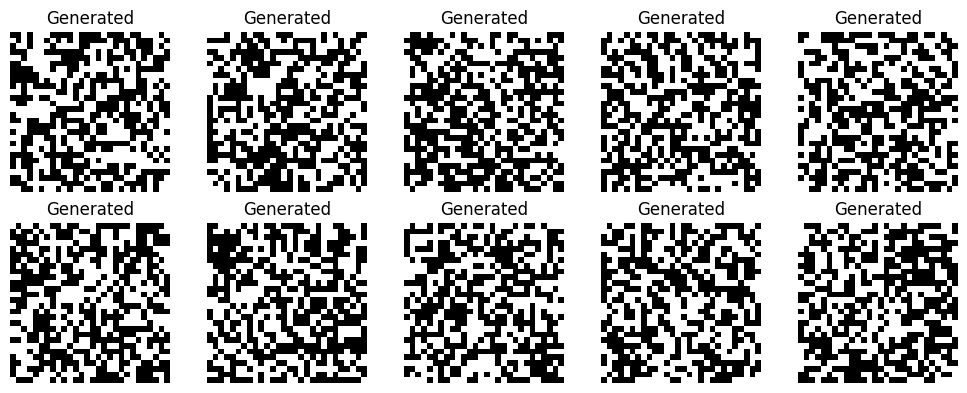

In [22]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.datasets import mnist
import time

np.random.seed(42)
tf.random.set_seed(42)

# Load and binarize MNIST
(x_train, _), (x_test, _) = mnist.load_data()

x_train = x_train[:5000].reshape(-1, 784)
x_test = x_test[:500].reshape(-1, 784)

x_train = (x_train > 127).astype(np.float32)
x_test = (x_test > 127).astype(np.float32)

def sigmoid(x):
    x = np.clip(x, -30, 30)
    return 1 / (1 + np.exp(-x))

# Single-layer RBM
class RBM:
    def __init__(self, visible, hidden):
        self.W = np.random.normal(0, 0.01, (visible, hidden))
        self.vb = np.zeros(visible)
        self.hb = np.zeros(hidden)

    def train(self, data, epochs=5, lr=0.01):
        errors = []

        for epoch in range(epochs):
            total_error = 0

            for start in range(0, len(data), 100):
                v0 = data[start:start+100]

                ph0 = sigmoid(v0 @ self.W + self.hb)
                h0 = (np.random.rand(*ph0.shape) < ph0).astype(np.float32)

                pv1 = sigmoid(h0 @ self.W.T + self.vb)
                ph1 = sigmoid(pv1 @ self.W + self.hb)

                self.W += lr * (
                    v0.T @ ph0 - pv1.T @ ph1
                ) / len(v0)

                self.vb += lr * np.mean(v0 - pv1, axis=0)
                self.hb += lr * np.mean(ph0 - ph1, axis=0)

                total_error += np.mean((v0 - pv1) ** 2)

            errors.append(total_error / (len(data) / 100))
            print("RBM Epoch", epoch + 1, "Error:", errors[-1])

        return errors

    def reconstruct(self, data):
        hidden = sigmoid(data @ self.W + self.hb)
        return sigmoid(hidden @ self.W.T + self.vb)

# Two-hidden-layer DBM-style model
class DBM:
    def __init__(self, visible=784, hidden1=128, hidden2=64):
        self.W1 = np.random.normal(0, 0.01, (visible, hidden1))
        self.W2 = np.random.normal(0, 0.01, (hidden1, hidden2))

        self.vb = np.zeros(visible)
        self.b1 = np.zeros(hidden1)
        self.b2 = np.zeros(hidden2)

    # Mean-field inference
    def mean_field(self, v, steps=5):
        h1 = np.zeros((len(v), self.W1.shape[1]))
        h2 = np.zeros((len(v), self.W2.shape[1]))

        for _ in range(steps):
            h1 = sigmoid(v @ self.W1 + h2 @ self.W2.T + self.b1)
            h2 = sigmoid(h1 @ self.W2 + self.b2)

        return h1, h2

    # Approximate learning using mean-field and Gibbs sampling
    def train(self, data, epochs=5, lr=0.005):
        errors = []

        for epoch in range(epochs):
            total_error = 0

            for start in range(0, len(data), 100):
                v0 = data[start:start+100]

                h10, h20 = self.mean_field(v0)

                # Gibbs sampling
                h2_sample = (
                    np.random.rand(*h20.shape) < h20
                ).astype(np.float32)

                h1_sample = (
                    np.random.rand(*h10.shape) <
                    sigmoid(v0 @ self.W1 + h2_sample @ self.W2.T + self.b1)
                ).astype(np.float32)

                v1_prob = sigmoid(h1_sample @ self.W1.T + self.vb)

                h1_negative = sigmoid(
                    v1_prob @ self.W1 +
                    h2_sample @ self.W2.T + self.b1
                )

                h2_negative = sigmoid(h1_negative @ self.W2 + self.b2)

                # Update weights
                self.W1 += lr * (
                    v0.T @ h10 - v1_prob.T @ h1_negative
                ) / len(v0)

                self.W2 += lr * (
                    h10.T @ h20 - h1_negative.T @ h2_negative
                ) / len(v0)

                self.vb += lr * np.mean(v0 - v1_prob, axis=0)
                self.b1 += lr * np.mean(h10 - h1_negative, axis=0)
                self.b2 += lr * np.mean(h20 - h2_negative, axis=0)

                total_error += np.mean((v0 - v1_prob) ** 2)

            errors.append(total_error / (len(data) / 100))
            print("DBM Epoch", epoch + 1, "Error:", errors[-1])

        return errors

    def reconstruct(self, data):
        h1, h2 = self.mean_field(data)
        return sigmoid(h1 @ self.W1.T + self.vb)

# Train RBM
start = time.time()
rbm = RBM(784, 128)
rbm_errors = rbm.train(x_train, epochs=5)
rbm_time = time.time() - start

# Train DBM
start = time.time()
dbm = DBM()
dbm_errors = dbm.train(x_train, epochs=5)
dbm_time = time.time() - start

# Compare reconstruction errors
rbm_rec = rbm.reconstruct(x_test)
dbm_rec = dbm.reconstruct(x_test)

print("\nRBM Test Error:", np.mean((x_test-rbm_rec)**2))
print("DBM Test Error:", np.mean((x_test-dbm_rec)**2))
print("RBM Training Time:", round(rbm_time, 2), "seconds")
print("DBM Training Time:", round(dbm_time, 2), "seconds")

# Plot training errors
plt.figure(figsize=(8, 5))
plt.plot(rbm_errors, marker="o", label="Single-layer RBM")
plt.plot(dbm_errors, marker="s", label="Two-layer DBM")
plt.xlabel("Epoch")
plt.ylabel("Reconstruction Error")
plt.title("RBM vs DBM Training")
plt.legend()
plt.grid()
plt.show()

# Display original and reconstructed images
fig, ax = plt.subplots(3, 5, figsize=(12, 7))

for i in range(5):
    ax[0, i].imshow(x_test[i].reshape(28, 28), cmap="gray")
    ax[0, i].set_title("Original")

    ax[1, i].imshow(rbm_rec[i].reshape(28, 28), cmap="gray")
    ax[1, i].set_title("RBM")

    ax[2, i].imshow(dbm_rec[i].reshape(28, 28), cmap="gray")
    ax[2, i].set_title("DBM")

    for j in range(3):
        ax[j, i].axis("off")

plt.tight_layout()
plt.show()

# Visualize DBM first-layer filters
fig, ax = plt.subplots(2, 5, figsize=(10, 5))

for i, a in enumerate(ax.ravel()):
    a.imshow(dbm.W1[:, i].reshape(28, 28), cmap="gray")
    a.set_title("Filter " + str(i+1))
    a.axis("off")

plt.tight_layout()
plt.show()

# Hidden-unit activations
h1, h2 = dbm.mean_field(x_test[:10])

plt.figure(figsize=(10, 4))
plt.imshow(h1, aspect="auto", cmap="viridis")
plt.title("DBM Hidden Layer 1 Activations")
plt.xlabel("Hidden Units")
plt.ylabel("Input Images")
plt.colorbar()
plt.show()

plt.figure(figsize=(8, 4))
plt.imshow(h2, aspect="auto", cmap="viridis")
plt.title("DBM Hidden Layer 2 Activations")
plt.xlabel("Hidden Units")
plt.ylabel("Input Images")
plt.colorbar()
plt.show()

# Generate samples using Gibbs sampling
v = np.random.binomial(1, 0.5, (10, 784)).astype(np.float32)

for _ in range(100):
    h1, h2 = dbm.mean_field(v)
    h2 = (np.random.rand(*h2.shape) < h2).astype(np.float32)
    h1 = (np.random.rand(*h1.shape) <
          sigmoid(v @ dbm.W1 + h2 @ dbm.W2.T + dbm.b1)).astype(np.float32)
    v = (np.random.rand(*v.shape) <
         sigmoid(h1 @ dbm.W1.T + dbm.vb)).astype(np.float32)

fig, ax = plt.subplots(2, 5, figsize=(10, 4))

for i, a in enumerate(ax.ravel()):
    a.imshow(v[i].reshape(28, 28), cmap="gray")
    a.set_title("Generated")
    a.axis("off")

plt.tight_layout()
plt.show()